# Module 3 — Dimensionality Reduction

**Biological question:** Gene expression data has ~6 000 dimensions (genes). Can we compress this into a 2D representation that still separates the five PAM50 breast cancer subtypes, and does the low-dimensional structure reveal technical batch effects that could confound downstream analyses?

**Method:**

- **PCA** — linear projection that maximises variance. Fast, deterministic, interpretable via explained variance. We use 50 components as a first reduction step.
- **UMAP** — non-linear manifold learning. Preserves local neighbourhood structure better than PCA for visualisation. Applied on top of PCA-50 to improve speed and reduce noise.

**Batch effect check:** TCGA samples come from many tissue source sites (TSS). If PCA colour-coded by TSS shows the same clusters as colour-coded by subtype, the biological signal dominates. If TSS clusters appear separately from subtypes, a batch correction step (e.g. ComBat) would be warranted before modelling.


In [1]:
import sys
sys.path.insert(0, "..")

import logging
import matplotlib.pyplot as plt
import pandas as pd

from src.constants import InterimFile
from src.paths import interim_file
from src.features.dimensionality_reduction import run_pca, run_umap
from src.visualization.embeddings import plot_embedding, plot_scree

logging.basicConfig(level=logging.INFO, format="%(message)s")

## Load Data


In [2]:
X = pd.read_csv(interim_file(InterimFile.X), index_col=0)
labels = pd.read_csv(interim_file(InterimFile.LABELS), index_col=0).squeeze()

# Extract tissue source site from TCGA barcode (3rd field, e.g. TCGA-A1-XXXX)
tss = labels.index.to_series().str.split("-").str[1]
tss.name = "tissue_source_site"

print(f"X:      {X.shape[0]:>5} samples × {X.shape[1]:>5} genes")
print(f"labels: {labels.value_counts().to_dict()}")

X:        842 samples ×  6000 genes
labels: {'LumA': 421, 'LumB': 192, 'Basal': 139, 'Her2': 67, 'Normal': 23}


## PCA — Scree Plot

The scree plot shows how much variance each principal component captures. We look for an 'elbow' where additional components give diminishing returns. We also track the cumulative explained variance to decide how many components to keep for downstream steps (UMAP, classification).


PCA: 50 components, top-10 explain 38.3% variance


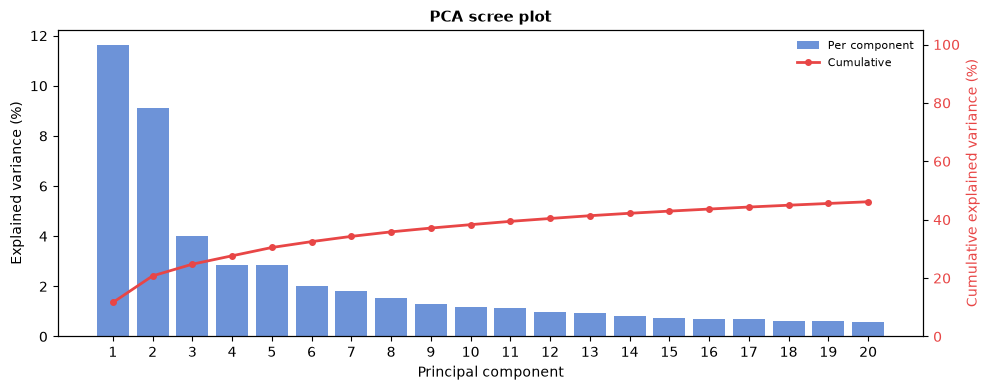

In [3]:
pca_emb, pca = run_pca(X, n_components=50)

fig, ax = plt.subplots(figsize=(10, 4))
plot_scree(pca, n_components=20, ax=ax)
plt.tight_layout()
plt.show()

## PCA 2D — Coloured by PAM50 Subtype

PC1 and PC2 alone often separate the most molecularly distinct subtypes (Basal vs luminal). A clean cluster separation here confirms that the dominant variance in the data tracks PAM50 biology, not noise.


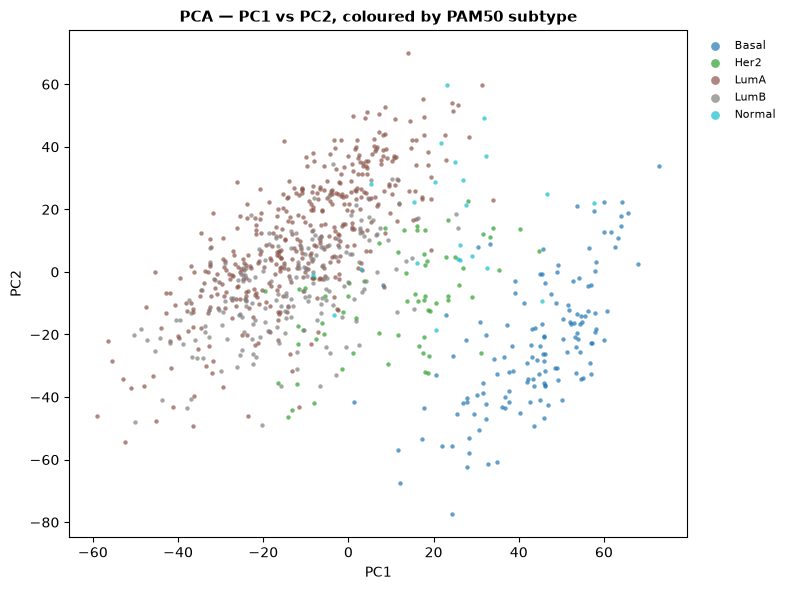

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_embedding(
    emb=pca_emb[["PC1", "PC2"]],
    labels=labels,
    title="PCA — PC1 vs PC2, coloured by PAM50 subtype",
    ax=ax,
)
plt.tight_layout()
plt.show()

## PCA 2D — Coloured by Tissue Source Site (Batch Check)

If TSS clusters overlap with PAM50 clusters, the biological signal dominates the PCA space and batch effects are not the primary driver. If TSS and subtype clusters align differently, consider ComBat or similar correction before modelling.

> **Interpretation guide:** In published TCGA BRCA analyses, PCA is predominantly driven by subtype (Basal separates clearly on PC1). Tissue source site variation is secondary and typically visible only on PC3–PC5. If you see strong TSS clustering on PC1/PC2 here, it likely means there are sample-level quality differences between batches.


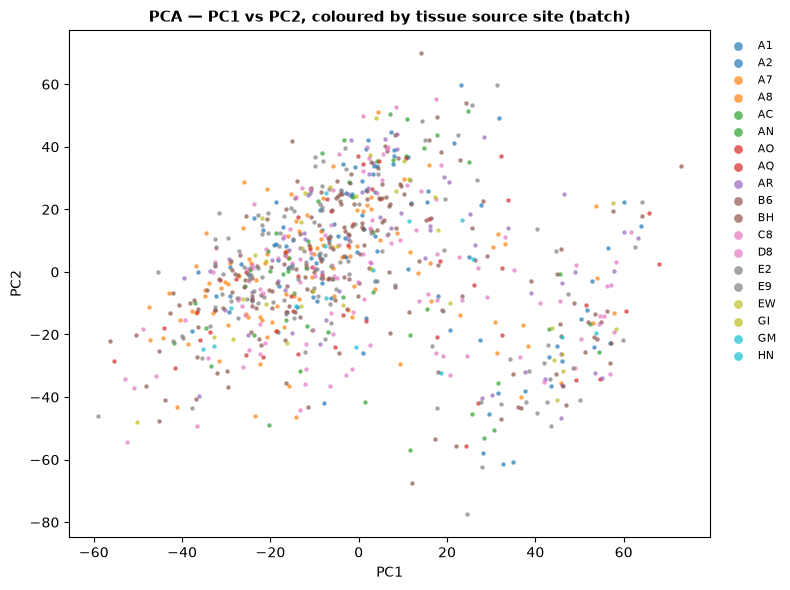

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_embedding(
    emb=pca_emb[["PC1", "PC2"]],
    labels=tss,
    title="PCA — PC1 vs PC2, coloured by tissue source site (batch)",
    ax=ax,
)
plt.tight_layout()
plt.show()

## UMAP — Coloured by PAM50 Subtype

UMAP is applied to PCA-50 (not raw expression) to reduce computation time and filter high-frequency noise. It tends to produce tighter, more visually separated clusters than PCA for the 2D view, at the cost of losing the linear interpretability of PCA axes.


D:\bioinformatics\cancer-genomics-ds\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP: 2 components on 842 × 50 input


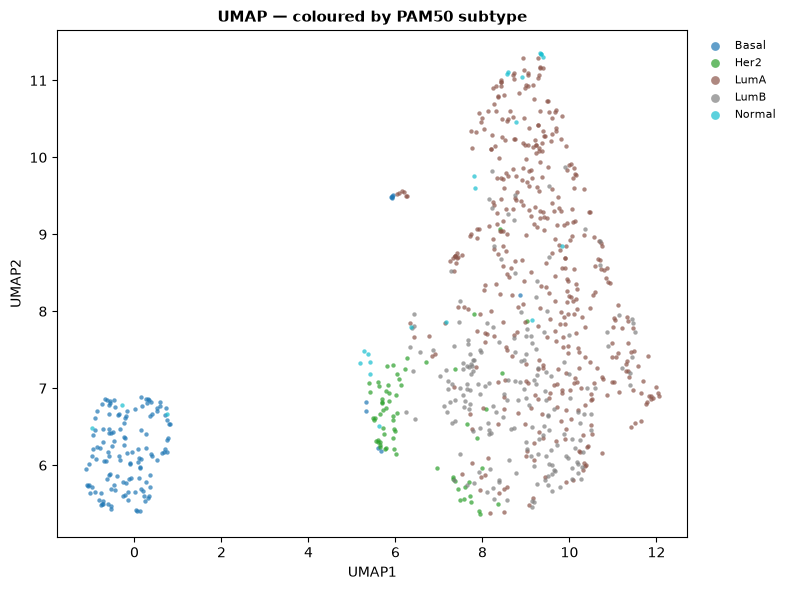

In [6]:
umap_emb = run_umap(pca_emb, n_components=2)

fig, ax = plt.subplots(figsize=(8, 6))
plot_embedding(
    emb=umap_emb,
    labels=labels,
    title="UMAP — coloured by PAM50 subtype",
    ax=ax,
)
plt.tight_layout()
plt.show()

## Save Embeddings


In [7]:
pca_out = interim_file(InterimFile.PCA_EMBEDDINGS)
pca_emb.to_csv(pca_out)
print(f"Saved {pca_out.name}  ({pca_emb.shape[0]} samples × {pca_emb.shape[1]} components)")

umap_out = interim_file(InterimFile.UMAP_EMBEDDINGS)
umap_emb.to_csv(umap_out)
print(f"Saved {umap_out.name}  ({umap_emb.shape[0]} samples × {umap_emb.shape[1]} components)")

Saved pca_embeddings.csv.gz  (842 samples × 50 components)
Saved umap_embeddings.csv.gz  (842 samples × 2 components)
